In [1]:
from neo4j import GraphDatabase

URI = "bolt://127.0.0.1:7687"
AUTH = ("neo4j", "alie.110705")

driver = GraphDatabase.driver(URI, auth=AUTH)

try:
    driver.verify_connectivity()
    print("Koneksi Neo4j berhasil!")

    with driver.session(database="uts") as session:
        
        result = session.run("RETURN 'Database terhubung' AS pesan")
        print(result.single()["pesan"])

finally:
    driver.close()

Koneksi Neo4j berhasil!
Database terhubung


In [2]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path("C:\\Anaconda\\envs\\uts-gsd\\events.csv")

if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)
    print("Dataset berhasil dibaca!")
    print("Ukuran data:", df.shape)
    display(df.head())
else:
    print("File belum ditemukan:", DATA_PATH.resolve())

Dataset berhasil dibaca!
Ukuran data: (2756101, 5)


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [3]:
import pandas as pd

# Ubah Unix timestamp menjadi tanggal dan waktu
df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    unit="ms",
    utc=True
)

# Periode P1: Training
p1_start = pd.Timestamp("2015-07-07", tz="UTC")
p1_end = pd.Timestamp("2015-07-10", tz="UTC")

# Periode P2: Testing
p2_start = pd.Timestamp("2015-07-11", tz="UTC")
p2_end = pd.Timestamp("2015-07-13", tz="UTC")

# Filter data berdasarkan rentang waktu
df_p1 = df[
    (df["timestamp"] >= p1_start) &
    (df["timestamp"] < p1_end)
].copy()

df_p2 = df[
    (df["timestamp"] >= p2_start) &
    (df["timestamp"] < p2_end)
].copy()

print("Jumlah data P1:", len(df_p1))
print("Jumlah data P2:", len(df_p2))

display(df_p1.head())

Jumlah data P1: 74417
Jumlah data P2: 41921


,timestamp,visitorid,event,itemid,transactionid
2153879,2015-07-07 05:47:17.701000+00:00,470756,view,292724,NaN
2153880,2015-07-07 05:54:07.185000+00:00,1312369,view,419150,NaN
2153881,2015-07-07 05:58:21.248000+00:00,558764,view,342357,NaN
2153882,2015-07-07 05:57:51.975000+00:00,1254959,view,94268,NaN
2153883,2015-07-07 05:51:54.535000+00:00,1305045,view,43447,NaN


In [4]:
from pathlib import Path

output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

df_p1.to_csv(output_dir / "retailrocket_P1_training.csv", index=False)
df_p2.to_csv(output_dir / "retailrocket_P2_testing.csv", index=False)

print("File berhasil disimpan:")
print(output_dir / "retailrocket_P1_training.csv")
print(output_dir / "retailrocket_P2_testing.csv")

File berhasil disimpan:
data\processed\retailrocket_P1_training.csv
data\processed\retailrocket_P2_testing.csv


In [5]:
print("P1:")
display(df_p1[["timestamp", "visitorid", "event", "itemid"]])

print("P2:")
display(df_p2[["timestamp", "visitorid", "event", "itemid"]])

P1:


,timestamp,visitorid,event,itemid
2153879,2015-07-07 05:47:17.701000+00:00,470756,view,292724
2153880,2015-07-07 05:54:07.185000+00:00,1312369,view,419150
2153881,2015-07-07 05:58:21.248000+00:00,558764,view,342357
2153882,2015-07-07 05:57:51.975000+00:00,1254959,view,94268
2153883,2015-07-07 05:51:54.535000+00:00,1305045,view,43447
...,...,...,...,...
2251788,2015-07-09 23:43:03.608000+00:00,169280,addtocart,50443
2251792,2015-07-09 23:43:11.885000+00:00,98810,view,385769
2251794,2015-07-09 23:32:17.855000+00:00,1109830,view,446820
2251798,2015-07-09 23:56:39.387000+00:00,754856,view,49556


P2:


,timestamp,visitorid,event,itemid
2252085,2015-07-12 00:02:04.836000+00:00,513205,view,43267
2252086,2015-07-11 23:21:15.852000+00:00,1378768,view,453772
2252087,2015-07-12 00:14:38.389000+00:00,270590,view,181021
2252088,2015-07-12 00:14:38.493000+00:00,1152109,view,144675
2252089,2015-07-11 22:37:24.534000+00:00,953880,view,18241
...,...,...,...,...
2316405,2015-07-12 21:40:17.399000+00:00,198171,view,271807
2316406,2015-07-12 20:57:51.908000+00:00,1344415,view,409253
2316407,2015-07-12 20:43:47.860000+00:00,631887,view,90684
2316408,2015-07-12 21:23:05.649000+00:00,814185,view,249689


In [6]:
from pathlib import Path

# Buat folder untuk menyimpan hasil
output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Simpan data P1 dan P2
df_p1.to_csv(
    output_dir / "retailrocket_P1_training.csv",
    index=False
)

df_p2.to_csv(
    output_dir / "retailrocket_P2_testing.csv",
    index=False
)

print("Data berhasil disimpan!")
print("Jumlah data P1:", len(df_p1))
print("Jumlah data P2:", len(df_p2))

Data berhasil disimpan!
Jumlah data P1: 74417
Jumlah data P2: 41921


In [7]:
print("File P1:", (output_dir / "retailrocket_P1_training.csv").exists())
print("File P2:", (output_dir / "retailrocket_P2_testing.csv").exists())

File P1: True
File P2: True


In [8]:
print("Kolom:", df_p1.columns.tolist())
print("Jumlah baris:", len(df_p1))
print("Jenis event:")
display(df_p1["event"].value_counts())

Kolom: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']
Jumlah baris: 74417
Jenis event:


event
view           71664
addtocart       2040
transaction      713
Name: count, dtype: int64

In [9]:
import pandas as pd

required_cols = [
    "timestamp", "visitorid", "event", "itemid", "transactionid"
]

missing_cols = [col for col in required_cols if col not in df_p1.columns]

if missing_cols:
    raise ValueError(f"Kolom belum tersedia: {missing_cols}")

# Bersihkan data yang tidak memiliki ID user/item atau event
data_p1 = df_p1.dropna(
    subset=["visitorid", "event", "itemid"]
).copy()

In [10]:
#impor database ke neo4j
def import_batch(tx, batch):
    query = """
    UNWIND $batch AS row

    MERGE (u:User {visitorid: row.visitorid})
    MERGE (i:Item {itemid: row.itemid})

    FOREACH (_ IN CASE WHEN row.event = 'view'
                       THEN [1] ELSE [] END |
        MERGE (u)-[:VIEWED {timestamp: row.timestamp}]->(i)
    )

    FOREACH (_ IN CASE WHEN row.event = 'addtocart'
                       THEN [1] ELSE [] END |
        MERGE (u)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
    )

    FOREACH (_ IN CASE WHEN row.event = 'transaction'
                       THEN [1] ELSE [] END |
        MERGE (u)-[:BOUGHT {
            timestamp: row.timestamp,
            transactionId: row.transactionid
        }]->(i)
    )
    """
    tx.run(query, batch=batch)

In [11]:
import pandas as pd

BATCH_SIZE = 5000

# Pastikan df_p1 berisi seluruh data periode P1
print("Jumlah baris df_p1:", len(df_p1))

p1 = df_p1.copy()

p1["visitorid"] = p1["visitorid"].astype(str)
p1["itemid"] = p1["itemid"].astype(str)
p1["event"] = p1["event"].astype(str)
p1["transactionid"] = (
    p1["transactionid"].astype("string").fillna("")
)
p1["timestamp"] = (
    pd.to_datetime(p1["timestamp"], utc=True)
    .dt.strftime("%Y-%m-%dT%H:%M:%S%z")
)

records = p1.to_dict("records")

print("Jumlah baris p1:", len(p1))
print("Jumlah records:", len(records))

Jumlah baris df_p1: 74417
Jumlah baris p1: 74417
Jumlah records: 74417


In [12]:
# BATCH_SIZE = 5000
# total = len(records)

# with driver.session(database="uts") as session:
#     for start in range(0, total, BATCH_SIZE):
#         batch = records[start:start + BATCH_SIZE]

#         session.write_transaction(import_batch, batch)

#         selesai = min(start + len(batch), total)
#         print(f"Berhasil diproses: {selesai:,}/{total:,}")

# print("Proses impor selesai!")

In [13]:
from neo4j import GraphDatabase

URI = "bolt://127.0.0.1:7687"
AUTH = ("neo4j", "alie.110705")

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()

print("Koneksi Neo4j berhasil!")

Koneksi Neo4j berhasil!


In [14]:
print("Jumlah baris P1:", len(df_p1))
print("Jumlah User unik P1:", df_p1["visitorid"].nunique())
print("Jumlah Item unik P1:", df_p1["itemid"].nunique())
print(
    "Total User + Item unik:",
    df_p1["visitorid"].nunique() + df_p1["itemid"].nunique()
)

Jumlah baris P1: 74417
Jumlah User unik P1: 40284
Jumlah Item unik P1: 34137
Total User + Item unik: 74421


In [15]:
# Menghitung jumlah setiap jenis simpul dalam subgraph
cypher_nodes = """
MATCH (n)
RETURN labels(n) AS jenis_simpul, COUNT(n) AS jumlah
ORDER BY jenis_simpul
"""

with driver.session(database="uts") as session:
    result = session.run(cypher_nodes)
    komposisi_simpul = [
        {
            "jenis_simpul": row["jenis_simpul"],
            "jumlah": row["jumlah"]
        }
        for row in result
    ]

import pandas as pd

df_komposisi = pd.DataFrame(komposisi_simpul)
print(df_komposisi)


  jenis_simpul  jumlah
0       [Item]   34137
1       [User]   40284


In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from scipy.sparse import csr_matrix

# Ambil interaksi User-Item dari data P1
interaksi = df_p1[["visitorid", "itemid"]].drop_duplicates().copy()

# Jadikan ID User dan Item sebagai indeks matriks
user_ids = interaksi["visitorid"].unique()
item_ids = interaksi["itemid"].unique()

user_to_idx = {user: idx for idx, user in enumerate(user_ids)}
item_to_idx = {item: idx for idx, item in enumerate(item_ids)}

row = interaksi["visitorid"].map(user_to_idx).to_numpy()
col = interaksi["itemid"].map(item_to_idx).to_numpy()
data = np.ones(len(interaksi), dtype=np.int8)

# Matriks VSM User-Item
X = csr_matrix(
    (data, (row, col)),
    shape=(len(user_ids), len(item_ids))
)

print("Jumlah interaksi unik:", len(interaksi))
print("Jumlah User:", len(user_ids))
print("Jumlah Item:", len(item_ids))
print("Shape VSM:", X.shape)
print("Dimensi matriks:", X.ndim)
print("Jumlah elemen non-zero:", X.nnz)
print("Kerapatan matriks:", X.nnz / (X.shape[0] * X.shape[1]))

Jumlah interaksi unik: 59395
Jumlah User: 40284
Jumlah Item: 34137
Shape VSM: (40284, 34137)
Dimensi matriks: 2
Jumlah elemen non-zero: 59395
Kerapatan matriks: 4.3190869506470085e-05


In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity

# Pastikan kolom ID menggunakan tipe string
df_vsm = df_p1[["visitorid", "itemid", "event"]].copy()
df_vsm["visitorid"] = df_vsm["visitorid"].astype(str)
df_vsm["itemid"] = df_vsm["itemid"].astype(str)

# Membuat indeks User dan Item
users = sorted(df_vsm["visitorid"].unique())
items = sorted(df_vsm["itemid"].unique())

user_to_idx = {user: idx for idx, user in enumerate(users)}
item_to_idx = {item: idx for idx, item in enumerate(items)}

# Mengubah ID menjadi indeks matriks
row_idx = df_vsm["visitorid"].map(user_to_idx).to_numpy()
col_idx = df_vsm["itemid"].map(item_to_idx).to_numpy()

# Nilai interaksi biner: 1 jika ada interaksi
data = np.ones(len(df_vsm), dtype=np.int8)

# CSR otomatis menggabungkan pasangan User-Item yang berulang
X = csr_matrix(
    (data, (row_idx, col_idx)),
    shape=(len(users), len(items)),
    dtype=np.int8
)

# Ubah seluruh nilai nonzero menjadi 1
X.data[:] = 1
X.eliminate_zeros()

print("Shape matriks VSM:", X.shape)
print("Jumlah User:", len(users))
print("Jumlah Item:", len(items))
print("Jumlah pasangan User-Item unik:", X.nnz)
print("Total elemen matriks:", X.shape[0] * X.shape[1])
print("Sparsity:", round(
    (1 - X.nnz / (X.shape[0] * X.shape[1])) * 100, 4
), "%")


Shape matriks VSM: (40284, 34137)
Jumlah User: 40284
Jumlah Item: 34137
Jumlah pasangan User-Item unik: 59395
Total elemen matriks: 1375174908
Sparsity: 99.9957 %


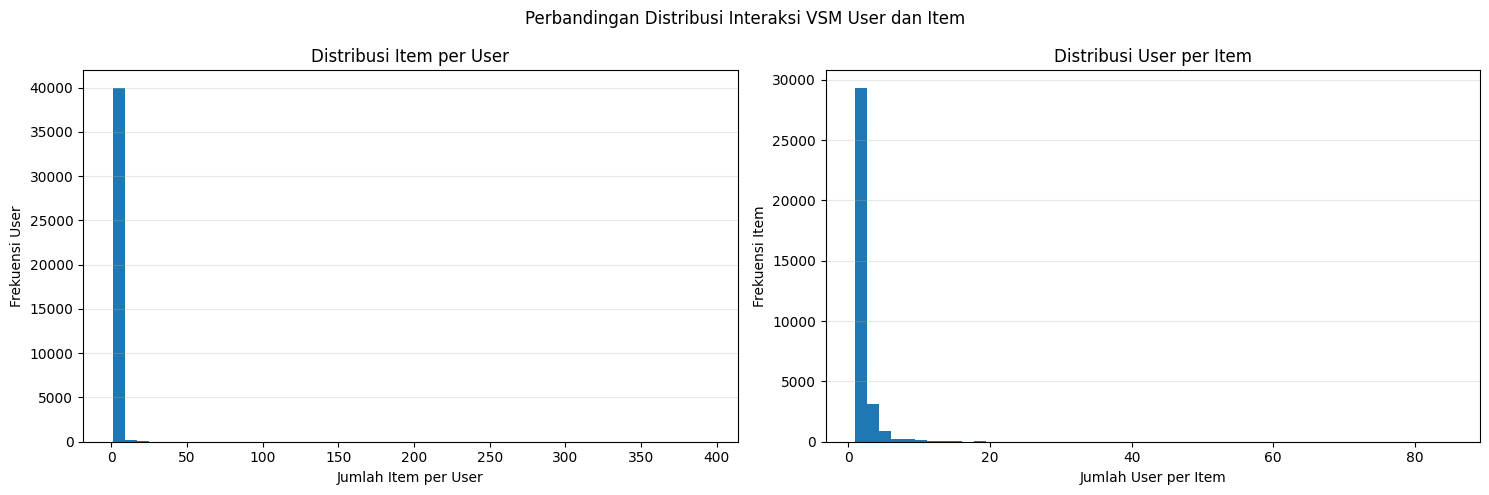

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Pastikan X_item sudah dibuat
X_item = X.T.tocsr()

# Hitung jumlah item per User
items_per_user = np.asarray(X.sum(axis=1)).ravel()

# Hitung jumlah User per Item
users_per_item = np.asarray(X_item.sum(axis=1)).ravel()

# Plot perbandingan dalam satu figure
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Grafik 1: Item per User
axes[0].hist(items_per_user, bins=50)
axes[0].set_xlabel("Jumlah Item per User")
axes[0].set_ylabel("Frekuensi User")
axes[0].set_title("Distribusi Item per User")
axes[0].grid(axis="y", alpha=0.3)

# Grafik 2: User per Item
axes[1].hist(users_per_item, bins=50)
axes[1].set_xlabel("Jumlah User per Item")
axes[1].set_ylabel("Frekuensi Item")
axes[1].set_title("Distribusi User per Item")
axes[1].grid(axis="y", alpha=0.3)

plt.suptitle("Perbandingan Distribusi Interaksi VSM User dan Item")
plt.tight_layout()
plt.show()

In [19]:
import pandas as pd

# VSM User: baris = User, kolom = Item
# VSM Item: baris = Item, kolom = User
X_item = X.T.tocsr()

def karakteristik_vsm(matriks, nama):
    total_elemen = matriks.shape[0] * matriks.shape[1]
    sparsity = (1 - matriks.nnz / total_elemen) * 100
    density = 100 - sparsity

    # Jumlah pasangan unik antarentitas dalam proyeksi
    n_entitas = matriks.shape[0]
    pasangan_unik = n_entitas * (n_entitas - 1) // 2

    return {
        "Jenis VSM": nama,
        "Dimensi": matriks.ndim,
        "Shape": str(matriks.shape),
        "Jumlah User": X.shape[0],
        "Jumlah Item": X.shape[1],
        "Elemen Nonzero": matriks.nnz,
        "Total Elemen": total_elemen,
        "Sparsity (%)": round(sparsity, 4),
        "Density (%)": round(density, 4),
        "Jumlah Pasangan Unik": pasangan_unik
    }

# Perbandingan VSM User dan VSM Item
df_perbandingan = pd.DataFrame([
    karakteristik_vsm(X, "VSM User"),
    karakteristik_vsm(X_item, "VSM Item")
])

print("PERBANDINGAN KARAKTERISTIK VSM USER DAN ITEM")
display(df_perbandingan)


PERBANDINGAN KARAKTERISTIK VSM USER DAN ITEM


,Jenis VSM,Dimensi,Shape,Jumlah User,Jumlah Item,Elemen Nonzero,Total Elemen,Sparsity (%),Density (%),Jumlah Pasangan Unik
0,VSM User,2,"(40284, 34137)",40284,34137,59395,1375174908,99.9957,0.0043,811380186
1,VSM Item,2,"(34137, 40284)",40284,34137,59395,1375174908,99.9957,0.0043,582650316


In [20]:
from sklearn.preprocessing import normalize

# Normalisasi VSM User (User × Item)
Xn = normalize(X, norm="l2", axis=1)

print("Shape Xn:", Xn.shape)

Shape Xn: (40284, 34137)


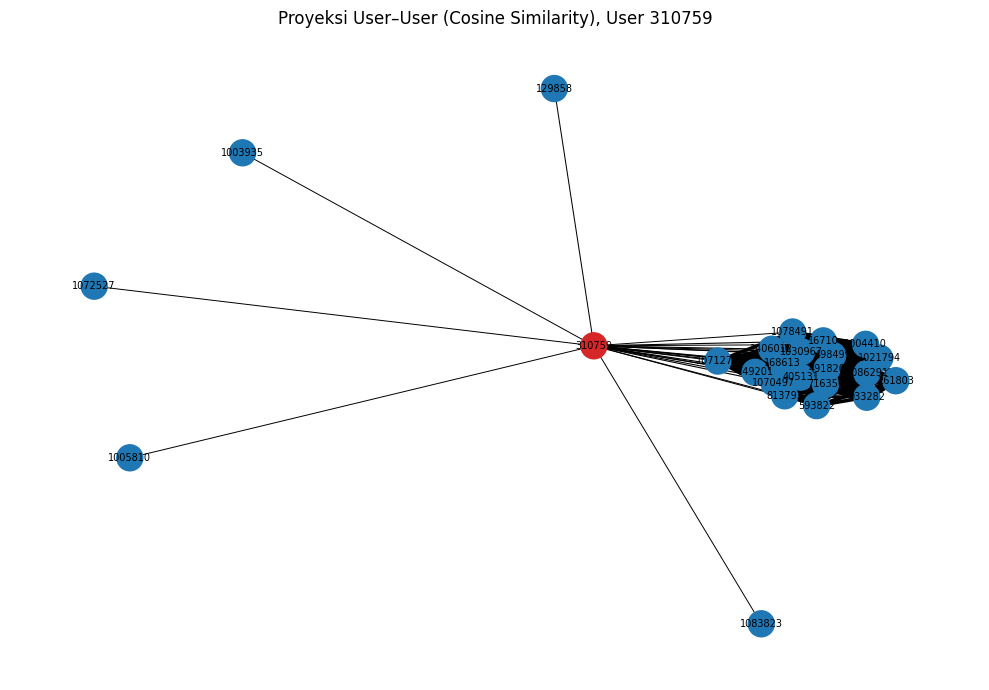

Jumlah simpul: 25
Jumlah sisi: 190


In [21]:
SEED = 42

def top_k_similar(Mn, idx, k):
    # Menghitung cosine similarity terhadap seluruh user
    sims = (Mn[idx] @ Mn.T).toarray().ravel()

    # Menghapus user itu sendiri dari hasil
    sims[idx] = -1.0

    # Memilih k user dengan similarity tertinggi
    order = np.argsort(-sims, kind="stable")[:k]

    # Hanya mempertahankan similarity positif
    order = order[sims[order] > 0]

    return order, sims[order]

def plot_ego(Mn, ids, idx, k, title):
    nbr, similarities = top_k_similar(Mn, idx, k)
    nodes = [idx] + list(nbr)

    # Menghitung similarity antarseluruh user terpilih
    sub = Mn[nodes]
    S = (sub @ sub.T).toarray()

    G = nx.Graph()

    for i in nodes:
        G.add_node(
            str(ids[i]),
            user_id=str(ids[i]),
            is_center=(i == idx)
        )

    # Menambahkan sisi berdasarkan cosine similarity
    for a in range(len(nodes)):
        for b in range(a + 1, len(nodes)):
            if S[a, b] > 0:
                G.add_edge(
                    str(ids[nodes[a]]),
                    str(ids[nodes[b]]),
                    weight=float(S[a, b])
                )

    pos = nx.spring_layout(
        G,
        seed=SEED,
        weight="weight"
    )

    colors = [
        "tab:red" if G.nodes[n]["is_center"] else "tab:blue"
        for n in G.nodes
    ]

    widths = [
        0.5 + 4 * G[u][v]["weight"]
        for u, v in G.edges
    ]

    plt.figure(figsize=(10, 7))

    nx.draw_networkx(
        G,
        pos,
        node_color=colors,
        width=widths,
        node_size=350,
        font_size=7,
        with_labels=True
    )

    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

    return G

# Menentukan user dengan interaksi terbanyak
ref_user_idx = int(np.argmax(np.diff(X.indptr)))

# Pastikan urutan users sama dengan urutan baris X
G_user = plot_ego(
    Xn,
    users,
    ref_user_idx,
    24,
    f"Proyeksi User–User (Cosine Similarity), User {users[ref_user_idx]}"
)

print("Jumlah simpul:", G_user.number_of_nodes())
print("Jumlah sisi:", G_user.number_of_edges())

In [22]:
from sklearn.preprocessing import normalize
import numpy as np

# Membuat VSM Item (Item × User)
XT = X.T.tocsr()

# Normalisasi setiap baris item
XTn = normalize(XT, norm="l2", axis=1)

print("Shape VSM Item:", XT.shape)
print("Jumlah nilai tidak nol (nnz):", f"{XT.nnz:,}")

Shape VSM Item: (34137, 40284)
Jumlah nilai tidak nol (nnz): 59,395


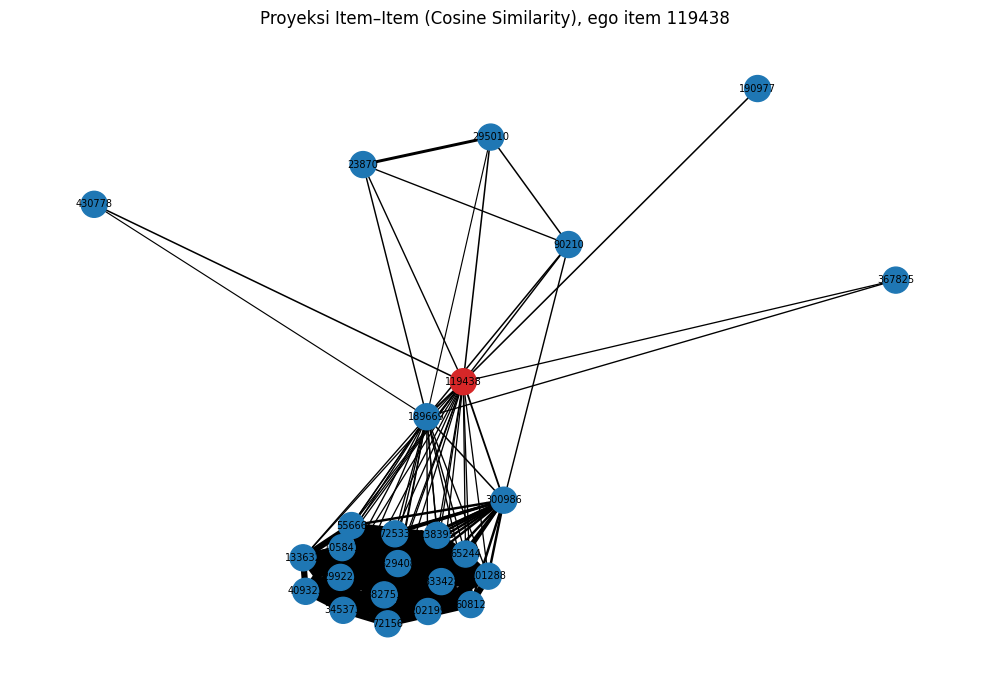

Jumlah simpul: 25
Jumlah sisi: 186


In [23]:
# Graf proyeksi Item–Item

# Jumlah user unik yang berinteraksi dengan setiap item
users_per_item = np.diff(XT.indptr)

# Memilih item dengan interaksi terbanyak
ref_item_idx = int(np.argmax(users_per_item))

# Memvisualisasikan maksimal 24 item yang paling mirip
G_item = plot_ego(
    XTn,
    item_ids,
    ref_item_idx,
    24,
    f"Proyeksi Item–Item (Cosine Similarity), "
    f"ego item {item_ids[ref_item_idx]}"
)

print("Jumlah simpul:", G_item.number_of_nodes())
print("Jumlah sisi:", G_item.number_of_edges())

In [24]:
import numpy as np
import pandas as pd
from sklearn.neighbors import NearestNeighbors

# Memastikan matriks VSM Item tersedia
print("Shape VSM Item:", X_item.shape)

# Model pencarian tetangga terdekat berdasarkan cosine distance
knn_item = NearestNeighbors(
    n_neighbors=6,  # 1 item itu sendiri + 5 item terdekat
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

knn_item.fit(X_item)

# Pilih 10 Item dengan jumlah User terbanyak sebagai sampel
users_per_item = np.asarray(X_item.sum(axis=1)).ravel()
n_sample = min(10, len(items))
sample_idx = np.argsort(-users_per_item)[:n_sample]

results = []

for idx in sample_idx:
    # Cari 5 Item paling mirip dengan Item saat ini
    distances, indices = knn_item.kneighbors(
        X_item[idx],
        n_neighbors=6
    )

    source_item = items[idx]

    for distance, neighbor_idx in zip(
        distances[0], indices[0]
    ):
        # Hilangkan Item yang dibandingkan dengan dirinya sendiri
        if neighbor_idx == idx:
            continue

        similarity = 1 - distance

        results.append({
            "Item": source_item,
            "Item_Mirip": items[neighbor_idx],
            "Cosine_Similarity": round(float(similarity), 4)
        })

        # Cukup ambil 5 tetangga selain dirinya sendiri
        if sum(r["Item"] == source_item for r in results) >= 5:
            break

df_similarity = pd.DataFrame(results)

print("Hasil similarity antar-Item:")
display(df_similarity.head(10))

Shape VSM Item: (34137, 40284)
Hasil similarity antar-Item:


,Item,Item_Mirip,Cosine_Similarity
0,365673,184903,0.2317
1,365673,184465,0.2058
2,365673,257551,0.1534
3,365673,365692,0.1534
4,365673,446565,0.1534
5,184903,365673,0.2317
6,184903,407692,0.1794
7,184903,131874,0.1678
8,184903,390036,0.1678
9,184903,184465,0.1501


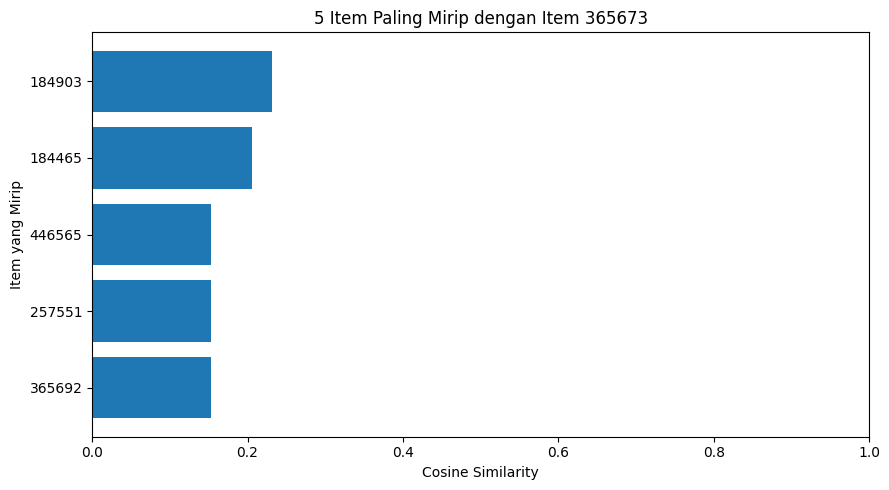

In [25]:
# Pilih Item pertama dari hasil similarity
target_item = df_similarity["Item"].iloc[0]

plot_data = (
    df_similarity[df_similarity["Item"] == target_item]
    .sort_values("Cosine_Similarity", ascending=True)
)

plt.figure(figsize=(9, 5))
plt.barh(
    plot_data["Item_Mirip"].astype(str),
    plot_data["Cosine_Similarity"]
)

plt.xlabel("Cosine Similarity")
plt.ylabel("Item yang Mirip")
plt.title(f"5 Item Paling Mirip dengan Item {target_item}")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()


In [26]:
# Pilih Item acuan dari hasil similarity
target_item = df_similarity["Item"].iloc[0]

# Ambil 5 item paling mirip dengan target_item
df_top5 = (
    df_similarity[df_similarity["Item"] == target_item]
    .sort_values("Cosine_Similarity", ascending=False)
    .head(5)
)

display(df_top5)

,Item,Item_Mirip,Cosine_Similarity
0,365673,184903,0.2317
1,365673,184465,0.2058
2,365673,257551,0.1534
3,365673,365692,0.1534
4,365673,446565,0.1534


In [27]:
# Ubah hasil menjadi list of dictionaries
rows = [
    {
        "item": str(row["Item"]),
        "item_mirip": str(row["Item_Mirip"]),
        "similarity": float(row["Cosine_Similarity"])
    }
    for _, row in df_top5.iterrows()
]

cypher_insert = """
UNWIND $rows AS row
MATCH (a:Item)
WHERE toString(a.itemid) = row.item
MATCH (b:Item)
WHERE toString(b.itemid) = row.item_mirip
MERGE (a)-[r:SIMILAR_TO]->(b)
SET r.similarity = row.similarity
RETURN
    a.itemid AS Item,
    b.itemid AS Item_Mirip,
    r.similarity AS Cosine_Similarity
ORDER BY Cosine_Similarity DESC
"""

with driver.session(database="uts") as session:
    result = session.run(cypher_insert, rows=rows)
    hasil_simpan = [dict(record) for record in result]

display(pd.DataFrame(hasil_simpan))

,Item,Item_Mirip,Cosine_Similarity
0,365673,184903,0.2317
1,365673,184465,0.2058
2,365673,365692,0.1534
3,365673,257551,0.1534
4,365673,446565,0.1534


In [28]:
rows = df_top5.to_dict(orient="records")

cypher_insert = """
UNWIND $rows AS row
MATCH (a:Item)
WHERE toString(a.itemid) = toString(row.Item)
MATCH (b:Item)
WHERE toString(b.itemid) = toString(row.Item_Mirip)
MERGE (a)-[r:SIMILAR_TO]->(b)
SET r.similarity = row.Cosine_Similarity
RETURN
    a.itemid AS Item,
    b.itemid AS Item_Mirip,
    r.similarity AS Cosine_Similarity
ORDER BY Cosine_Similarity DESC
"""

with driver.session(database="uts") as session:
    result = session.run(cypher_insert, rows=rows)
    hasil_query = [dict(record) for record in result]

display(pd.DataFrame(hasil_query))

,Item,Item_Mirip,Cosine_Similarity
0,365673,184903,0.2317
1,365673,184465,0.2058
2,365673,365692,0.1534
3,365673,257551,0.1534
4,365673,446565,0.1534


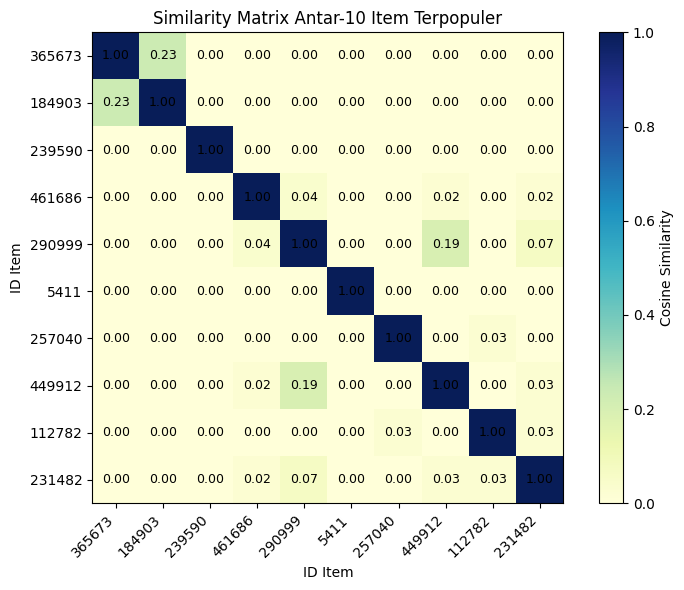

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity

# Pilih 10 item terpopuler
users_per_item = np.asarray(X_item.sum(axis=1)).ravel()
top_item_idx = np.argsort(-users_per_item)[:10]

# Ambil data 10 item
X_item_sample = X_item[top_item_idx]

# Hitung cosine similarity
S_item = cosine_similarity(X_item_sample)

# ID item sesuai urutan baris matriks
top_item_ids = [items[i] for i in top_item_idx]

# Plot similarity matrix tanpa seaborn
fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(
    S_item,
    cmap="YlGnBu",
    vmin=0,
    vmax=1
)

# Label sumbu dengan ID item
ax.set_xticks(np.arange(len(top_item_ids)))
ax.set_yticks(np.arange(len(top_item_ids)))
ax.set_xticklabels(top_item_ids, rotation=45, ha="right")
ax.set_yticklabels(top_item_ids)

# Tampilkan nilai similarity pada setiap sel
for i in range(S_item.shape[0]):
    for j in range(S_item.shape[1]):
        ax.text(
            j, i, f"{S_item[i, j]:.2f}",
            ha="center",
            va="center",
            color="black",
            fontsize=9
        )

# Colorbar dan judul
fig.colorbar(im, ax=ax, label="Cosine Similarity")
ax.set_title("Similarity Matrix Antar-10 Item Terpopuler")
ax.set_xlabel("ID Item")
ax.set_ylabel("ID Item")

plt.tight_layout()
plt.show()

In [30]:
import os
import numpy as np
import pandas as pd
from sklearn.preprocessing import normalize

SEED = 42
K_NEIGHBORS = 5
N_ADS = 3
N_REC = 5
MIN_P1_ITEMS = 5

P2_CSV = "data/processed/retailrocket_P2_testing.csv"
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

RELEVANT_EVENTS = ["view", "addtocart", "transaction"]

# VALIDASI VSM P1
if "X" not in globals():
    raise NameError("Matriks X belum ada. Jalankan sel pembentukan VSM P1 dahulu.")

if "user_ids" not in globals() or "item_ids" not in globals():
    raise NameError("user_ids/item_ids belum ada. Jalankan sel pembentukan VSM dahulu.")

user_ids = np.asarray(user_ids).astype(str)
item_ids = np.asarray(item_ids).astype(str)

if X.shape != (len(user_ids), len(item_ids)):
    raise ValueError(
        f"Urutan/dimensi ID tidak cocok: X={X.shape}, "
        f"user_ids={len(user_ids)}, item_ids={len(item_ids)}"
    )

X = X.tocsr()
Xn = normalize(X, norm="l2", axis=1)

user_pos = {u: i for i, u in enumerate(user_ids)}

# Fungsi cosine similarity antarpengguna
def top_k_similar(Mn, idx, k):
    sims = (Mn[idx] @ Mn.T).toarray().ravel()
    sims[idx] = -1.0
    order = np.argsort(-sims, kind="stable")[:k]
    order = order[sims[order] > 0]
    return order, sims[order]

# MENENTUKAN ITEM RELEVAN
test = pd.read_csv(P2_CSV, dtype=str)

required_cols = {"visitorid", "itemid", "event"}
if not required_cols.issubset(test.columns):
    raise ValueError(
        f"Kolom CSV harus mencakup {required_cols}. "
        f"Kolom yang ditemukan: {list(test.columns)}"
    )

test = test[test["event"].str.lower().isin(RELEVANT_EVENTS)].copy()
test["visitorid"] = test["visitorid"].astype(str)
test["itemid"] = test["itemid"].astype(str)

truth = test.groupby("visitorid")["itemid"].apply(set).to_dict()

# User yang muncul di P1 dan P2
in_both = [u for u in user_ids if u in truth]

# Item yang telah diakses pada P1
seen_p1 = {
    u: set(item_ids[X[user_pos[u]].indices])
    for u in in_both
}

# Item relevan baru di P2, tidak termasuk item P1
truth_new = {u: truth[u] - seen_p1[u] for u in in_both}

deg_user = np.diff(X.indptr)

eligible_orig = sorted(
    u for u in in_both
    if deg_user[user_pos[u]] >= MIN_P1_ITEMS
)
eligible = sorted(u for u in eligible_orig if truth_new[u])

print("User di P1 dan P2:", len(in_both))
print("Kandidat memenuhi minimum item P1:", len(eligible_orig))
print("Kandidat dengan item relevan baru di P2:", len(eligible))

if not eligible:
    raise RuntimeError(
        "Tidak ada user yang memenuhi syarat. "
        "Periksa periode P1/P2, event relevan, dan ID user."
    )

User di P1 dan P2: 771
Kandidat memenuhi minimum item P1: 18
Kandidat dengan item relevan baru di P2: 18


In [31]:
# FUNGSI REKOMENDASI USER-BASED KNN

def recommend_knn(u_idx, k=K_NEIGHBORS, n_rec=N_REC):
    nbr, sims = top_k_similar(Xn, u_idx, k)

    # Skor item berdasarkan jumlah similarity tetangga
    scores = np.asarray(X[nbr].T @ sims).ravel()

    # Jangan rekomendasikan item yang sudah diakses di P1
    scores[X[u_idx].indices] = 0

    order = np.argsort(-scores, kind="stable")[:n_rec]
    order = order[scores[order] > 0]

    return order, scores[order], nbr, sims

# Item populer berdasarkan total bobot/interaksi P1
pop_order = np.argsort(
    -np.asarray(X.sum(axis=0)).ravel(),
    kind="stable"
)

def backfill(rec, u_idx, n=N_REC):
    seen = set(X[u_idx].indices)
    out = [int(j) for j in rec]

    for j in pop_order:
        if len(out) >= n:
            break
        if int(j) not in seen and int(j) not in out:
            out.append(int(j))
    return out

In [32]:
# MEMILIH USER YANG MEMENUHI SYARAT KNN

knn_len = {
    u: len(recommend_knn(user_pos[u])[0])
    for u in eligible
}

for need in range(N_ADS, 0, -1):
    eligible_knn = [
        u for u in eligible
        if knn_len[u] >= need
    ]
    if eligible_knn:
        break
else:
    raise RuntimeError(
        "Tidak ada kandidat dengan rekomendasi KNN. "
        "Periksa data P1 dan matriks X."
    )

print(
    f"User dengan KNN menghasilkan >= {N_ADS} item:",
    sum(v >= N_ADS for v in knn_len.values()),
    "dari", len(eligible)
)

if need < N_ADS:
    print(
        f"PERINGATAN: syarat diturunkan menjadi >= {need} item KNN."
    )
print("Kandidat akhir:", len(eligible_knn))

# 5. MEMILIH USER SECARA ACAK DAN REPRODUCIBLE

rng = np.random.default_rng(SEED)

ref_user = eligible_knn[int(rng.integers(len(eligible_knn)))]
ref_idx = user_pos[ref_user]

print(f"\nUser terpilih: {ref_user} [SEED={SEED}]")
print(
    "Jumlah item P1:", deg_user[ref_idx],
    "| Item baru relevan P2:", len(truth_new[ref_user])
)

User dengan KNN menghasilkan >= 3 item: 7 dari 18
Kandidat akhir: 7

User terpilih: 1083118 [SEED=42]
Jumlah item P1: 7 | Item baru relevan P2: 1


In [33]:
# MENAMPILKAN TETANGGA TERDEKAT

rec_idx, rec_scores, nbr_idx, nbr_sims = recommend_knn(ref_idx)

print(f"\nTetangga terdekat untuk user {ref_user}:")
display(
    pd.DataFrame({
        "visitorid": user_ids[nbr_idx],
        "cosine_similarity": nbr_sims
    })
)


Tetangga terdekat untuk user 1083118:


,visitorid,cosine_similarity
0,30289,0.074125


In [34]:
# Daftar rekomendasi

final_idx = backfill(rec_idx, ref_idx)

# Label sumber setiap item: KNN atau item populer
sources = (
    ["KNN"] * len(rec_idx)
    + ["backfill populer"] * (len(final_idx) - len(rec_idx))
)

rec_df = pd.DataFrame({
    "peringkat": np.arange(1, len(final_idx) + 1),
    "itemid": item_ids[final_idx],
    "sumber": sources,
    "skor KNN": list(rec_scores)
                  + [np.nan] * (len(final_idx) - len(rec_idx))
})

print(f"\nTop-{N_REC} rekomendasi:")
display(rec_df)

print(f"{N_ADS} item yang diiklankan:", rec_df["itemid"].head(N_ADS).tolist())

print(
    "Semua item iklan berasal dari KNN:",
    bool((rec_df["sumber"].head(N_ADS) == "KNN").all())
)


Top-5 rekomendasi:


,peringkat,itemid,sumber,skor KNN
0,1,15466,KNN,0.074125
1,2,306161,KNN,0.074125
2,3,69754,KNN,0.074125
3,4,182246,KNN,0.074125
4,5,36155,KNN,0.074125


3 item yang diiklankan: ['15466', '306161', '69754']
Semua item iklan berasal dari KNN: True


In [35]:
# HIT@N DAN NDCG@N

def hit_at_n(rec, rel, n):
    return int(any(r in rel for r in rec[:n]))

def dcg(gains):
    return sum(
        g / np.log2(i + 2)
        for i, g in enumerate(gains)
    )

def ndcg_at_n(rec, rel, n):
    gains = [
        1 if r in rel else 0
        for r in rec[:n]
    ]

    idcg = dcg([1] * min(len(rel), n))

    return dcg(gains) / idcg if idcg > 0 else 0.0

rel = truth_new[ref_user]
final_items = list(item_ids[final_idx])
knn_items = list(item_ids[rec_idx])

detail = pd.DataFrame({
    "peringkat": np.arange(1, len(final_items) + 1),
    "itemid": final_items,
    "sumber": rec_df["sumber"].values,
    "relevan (ada di P2)": [
        int(r in rel) for r in final_items
    ]
})

detail["gain / log2(peringkat+1)"] = (
    detail["relevan (ada di P2)"]
    / np.log2(detail["peringkat"] + 1)
)

print("\nDetail evaluasi rekomendasi:")
display(detail)

print(f"Jumlah item relevan baru pada P2: {len(rel)}")
print("Item relevan:", sorted(rel))

print(f"Hit@{N_REC} = {hit_at_n(final_items, rel, N_REC)}")
print(
    f"DCG@{N_REC} = "
    f"{dcg([1 if r in rel else 0 for r in final_items[:N_REC]]):.4f}"
)
print(
    f"IDCG@{N_REC} = "
    f"{dcg([1] * min(len(rel), N_REC)):.4f}"
)
print(f"NDCG@{N_REC} = {ndcg_at_n(final_items, rel, N_REC):.4f}")

print(
    f"\nTanpa backfill populer: "
    f"Hit@{N_REC} = {hit_at_n(knn_items, rel, N_REC)}, "
    f"NDCG@{N_REC} = {ndcg_at_n(knn_items, rel, N_REC):.4f}"
)


#simpan

hasil = pd.DataFrame([{
    "user": ref_user,
    "seed": SEED,
    "k": K_NEIGHBORS,
    "item_iklan": ";".join(final_items[:N_ADS]),
    "top5": ";".join(final_items[:N_REC]),
    "hit@5": hit_at_n(final_items, rel, N_REC),
    "ndcg@5": ndcg_at_n(final_items, rel, N_REC)
}])

output_path = os.path.join(OUT_DIR, "hasil_user_acak.csv")
hasil.to_csv(output_path, index=False)

print("\nHasil disimpan ke:", os.path.abspath(output_path))



Detail evaluasi rekomendasi:


,peringkat,itemid,sumber,relevan (ada di P2),gain / log2(peringkat+1)
0,1,15466,KNN,0,0.0
1,2,306161,KNN,0,0.0
2,3,69754,KNN,0,0.0
3,4,182246,KNN,0,0.0
4,5,36155,KNN,0,0.0


Jumlah item relevan baru pada P2: 1
Item relevan: ['204166']
Hit@5 = 0
DCG@5 = 0.0000
IDCG@5 = 1.0000
NDCG@5 = 0.0000

Tanpa backfill populer: Hit@5 = 0, NDCG@5 = 0.0000

Hasil disimpan ke: C:\Windows\system32\outputs\hasil_user_acak.csv
